# Practical 8: K-Means Clustering (Elbow Method and Silhouette Score)

**Subject:** Machine Learning  |  **Type:** Unsupervised learning, clustering

## Aim
Apply the **K-Means clustering algorithm** on a suitable open-access dataset to obtain the **optimal number of clusters** using the **Elbow** or **Silhouette** method.

## Datasets
- **Part A: Iris** (150 flowers, 4 measurements). We **ignore the species labels** while clustering, and use them only at the end to check the result.
- **Part B: Synthetic blobs** (5 well-separated groups) where the elbow and silhouette methods both agree.

## Steps
1. Scale the features
2. Elbow method (inertia vs k)
3. Silhouette score vs k, and silhouette diagrams
4. Fit the final model, plot clusters and centroids
5. Compare with the true species (external check)
6. K-Means from scratch (to explain the algorithm)
7. Part B: clear-cut example

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")

## Step 1: Load and scale (labels are NOT used for clustering)

In [2]:
iris = load_iris()
X = iris.data
y_true = iris.target                         # only used for the final comparison
Xs = StandardScaler().fit_transform(X)       # K-Means uses Euclidean distance, so scale
print("Shape:", Xs.shape)
pd.DataFrame(X, columns=iris.feature_names).describe().round(2)

Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## Step 2: Elbow method

For each k we compute the **inertia (WCSS)**: the sum of squared distances from each point to its cluster centre:

$$WCSS = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

Inertia **always decreases** as k grows (with k = n it is 0), so we look for the **elbow**: the k after which the improvement becomes small.

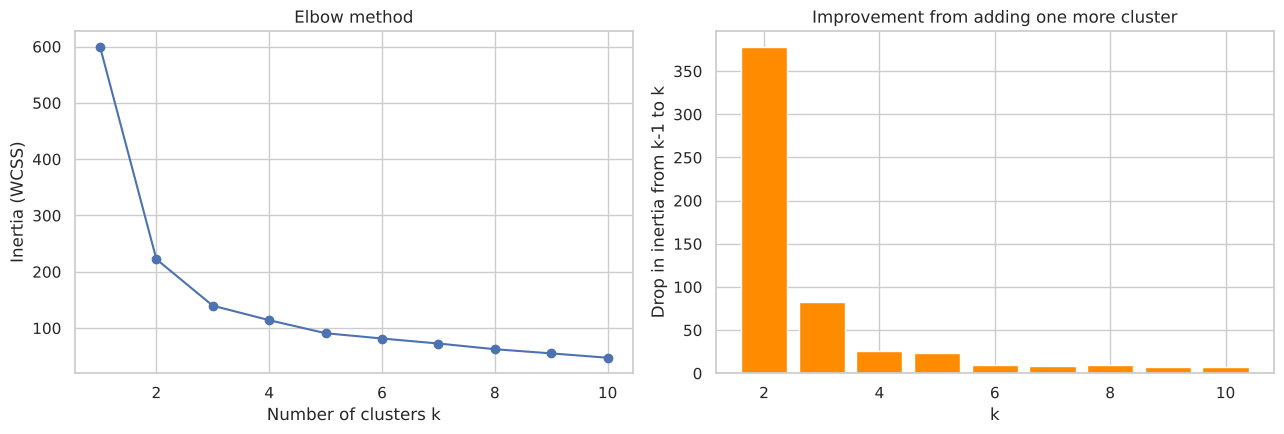

k          1.0    2.0    3.0    4.0   5.0   6.0   7.0   8.0   9.0  10.0
inertia  600.0  222.4  139.8  114.1  90.9  81.5  72.6  62.5  55.1  47.4


In [3]:
ks = range(1, 11)
inertia = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_xlabel("Number of clusters k"); ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method")
drop = -np.diff(inertia)
ax[1].bar(range(2, 11), drop, color="darkorange"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Drop in inertia from k-1 to k")
ax[1].set_title("Improvement from adding one more cluster")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1)}).T.to_string(header=False))

**How to read the elbow plot:** the line falls steeply at first and then flattens. The **elbow** is the bend where adding more clusters gives only small gains. For Iris the steepest drops are from k = 1 to 2 and from 2 to 3, and after k = 3 the curve flattens, so the elbow suggests **k = 3** (the right answer here: three species). The right-hand bar chart shows the same thing: big improvements up to k = 3 and small ones afterwards. The elbow is a *visual* judgement and can be ambiguous.

## Step 3: Silhouette score

For each point $i$: $s(i)=\dfrac{b(i)-a(i)}{\max(a(i),b(i))}$, where $a(i)$ is the mean distance to the other points in its own cluster and $b(i)$ is the mean distance to the points of the nearest other cluster. The score is between **-1 and +1**: near +1 = well clustered, near 0 = on the border between clusters, negative = probably in the wrong cluster. We choose the k with the **highest average silhouette score**.

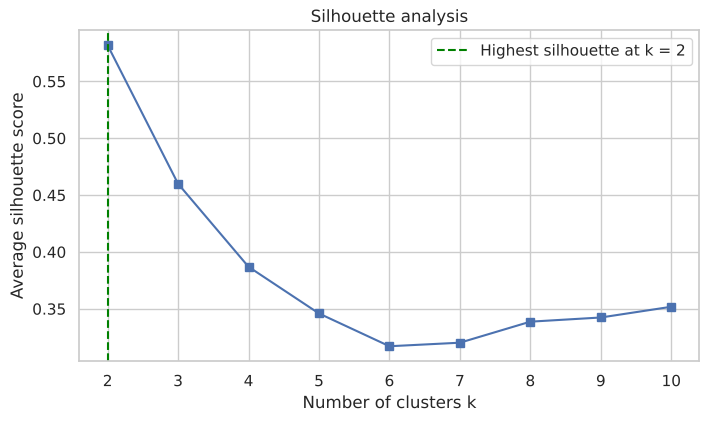

{2: 0.582, 3: 0.46, 4: 0.387, 5: 0.346, 6: 0.317, 7: 0.32, 8: 0.339, 9: 0.342, 10: 0.352}


In [4]:
sil = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil[k] = silhouette_score(Xs, km.labels_)

plt.figure(figsize=(8, 4.3))
plt.plot(list(sil.keys()), list(sil.values()), "s-")
best_k = max(sil, key=sil.get)
plt.axvline(best_k, color="green", ls="--", label=f"Highest silhouette at k = {best_k}")
plt.xlabel("Number of clusters k"); plt.ylabel("Average silhouette score"); plt.legend(); plt.title("Silhouette analysis")
plt.show()
print({k: round(v, 3) for k, v in sil.items()})

**How to read this:** the best k is the peak of the curve. On Iris the **silhouette score is highest at k = 2**, not 3. This is a classic viva question: *why do the two methods disagree?* Because *Iris versicolor and virginica overlap*, so geometrically the data looks like two groups (setosa, and versicolor+virginica together). The silhouette measures geometric separation, so it prefers k = 2, while we know biologically there are 3 species. **Neither method is "wrong"**: they answer slightly different questions, and the final choice should also use domain knowledge.

### Silhouette diagrams (per-sample view) for k = 2, 3, 4

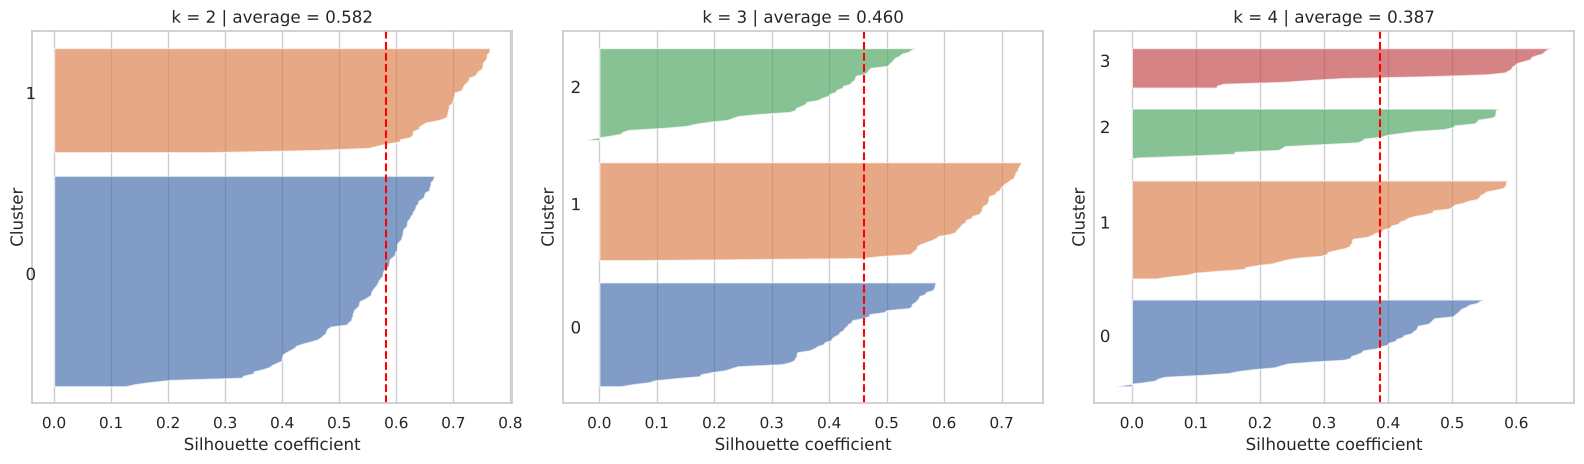

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, k in zip(axes, [2, 3, 4]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    vals = silhouette_samples(Xs, km.labels_)
    y_lower = 10
    for i in range(k):
        v = np.sort(vals[km.labels_ == i])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(v)), 0, v, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * len(v), str(i))
        y_lower += len(v) + 10
    ax.axvline(vals.mean(), color="red", ls="--")
    ax.set_title(f"k = {k} | average = {vals.mean():.3f}")
    ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Cluster")
    ax.set_yticks([])
plt.tight_layout(); plt.show()

**How to read a silhouette diagram:** each coloured "knife" is one cluster and each horizontal line is one sample, sorted by its silhouette value. The red dashed line is the average score (0.58 for k = 2, 0.46 for k = 3 in my run). A good clustering has knives of **similar width that all extend beyond the red line** and few or no samples below 0. For k = 3, look at the two clusters that contain versicolor and virginica: they are the ones whose knives are shorter and may dip below zero, because those two species overlap. Setosa's knife is the long, clean one. Check your own diagram for this pattern.

## Step 4: Fit the final model and visualise

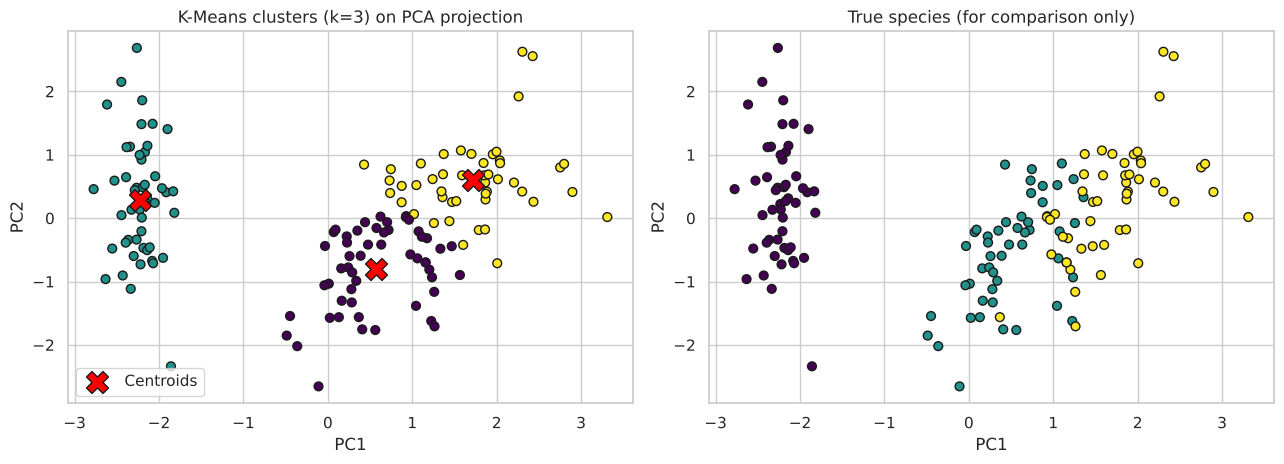

Cluster sizes: [53 50 47]


In [6]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
labels = km.labels_

pca = PCA(n_components=2).fit(Xs)
Xp = pca.transform(Xs)
cen = pca.transform(km.cluster_centers_)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(Xp[:, 0], Xp[:, 1], c=labels, cmap="viridis", edgecolor="k", s=40)
ax[0].scatter(cen[:, 0], cen[:, 1], c="red", marker="X", s=250, edgecolor="k", label="Centroids"); ax[0].legend()
ax[0].set_title(f"K-Means clusters (k={K}) on PCA projection")
ax[1].scatter(Xp[:, 0], Xp[:, 1], c=y_true, cmap="viridis", edgecolor="k", s=40)
ax[1].set_title("True species (for comparison only)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()
print("Cluster sizes:", np.bincount(labels))

**How to read these:** four features cannot be drawn directly, so PCA projects the data onto its two main axes. Left: the clusters found by K-Means with red X marks at the **centroids** (the mean of each cluster). Right: the true species. The clusterings look very similar: setosa is cleanly separated, while versicolor and virginica overlap, which is where the few mistakes are.

## Step 5: External check against the true species

In [7]:
print("Adjusted Rand Index (1 = perfect match): %.3f" % adjusted_rand_score(y_true, labels))
print("Davies-Bouldin (lower is better)       : %.3f" % davies_bouldin_score(Xs, labels))
print("Calinski-Harabasz (higher is better)   : %.1f" % calinski_harabasz_score(Xs, labels))
print("Silhouette                             : %.3f" % silhouette_score(Xs, labels))
print()
ct = pd.crosstab(pd.Series(y_true, name="True species").map(dict(enumerate(iris.target_names))),
                 pd.Series(labels, name="Cluster"))
ct

Adjusted Rand Index (1 = perfect match): 0.620
Davies-Bouldin (lower is better)       : 0.834
Calinski-Harabasz (higher is better)   : 241.9
Silhouette                             : 0.460



Cluster,0,1,2
True species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


**How to read the table:** each row is a true species and each column a K-Means cluster; the numbers are counts. In my run setosa falls entirely in one cluster (50 of 50). Versicolor is split 39 / 11 and virginica 36 / 14 between the other two clusters, so **25 of 150 flowers (about 17%) are grouped with the wrong species**. The Adjusted Rand Index is **0.62**: a moderate agreement, not a perfect one. (Without scaling, K-Means on Iris usually does a bit better, about 0.73, because petal measurements are the most informative features and scaling gives the less informative sepal width equal weight.) **Cluster numbers (0, 1, 2) are arbitrary labels**, so they need not match the species order.

## Step 6: K-Means from scratch (to explain the algorithm)

1. Choose k initial centroids. 2. Assign each point to its nearest centroid. 3. Move each centroid to the mean of its points. 4. Repeat 2 and 3 until the assignments stop changing.

Converged in 5 iterations | final inertia = 140.90 (sklearn: 139.82)
Agreement with sklearn (ARI): 0.832


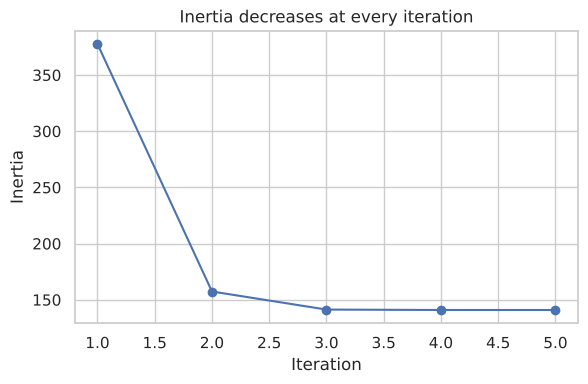

In [8]:
def kmeans_scratch(X, k, max_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), k, replace=False)]
    history = []
    for it in range(max_iter):
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)   # (n, k) distances
        lab = dist.argmin(axis=1)                                              # assignment step
        new = np.array([X[lab == j].mean(axis=0) if np.any(lab == j) else centroids[j] for j in range(k)])  # update step
        history.append(((X - new[lab]) ** 2).sum())
        if np.allclose(new, centroids):
            break
        centroids = new
    return lab, centroids, history

lab_s, cen_s, hist = kmeans_scratch(Xs, 3, seed=1)
print("Converged in", len(hist), "iterations | final inertia = %.2f (sklearn: %.2f)" % (hist[-1], km.inertia_))
print("Agreement with sklearn (ARI): %.3f" % adjusted_rand_score(labels, lab_s))
plt.figure(figsize=(6.5, 3.8)); plt.plot(range(1, len(hist) + 1), hist, "o-")
plt.xlabel("Iteration"); plt.ylabel("Inertia"); plt.title("Inertia decreases at every iteration"); plt.show()

**How to read this:** the inertia never increases and falls quickly in the first few iterations, then stops changing when the algorithm has **converged** (a local optimum). My scratch version converged in 5 iterations to inertia 140.9, slightly worse than scikit-learn's 139.8, and the agreement between the two clusterings (ARI) is 0.83 rather than 1.0. This is expected: K-Means only finds a **local optimum**, and a single random start can land in a slightly different one. That is why scikit-learn runs the algorithm `n_init` times from different starts and keeps the best.

## Part B: A clear-cut example (5 blobs)

When clusters are well separated, the elbow is sharp and silhouette agrees.

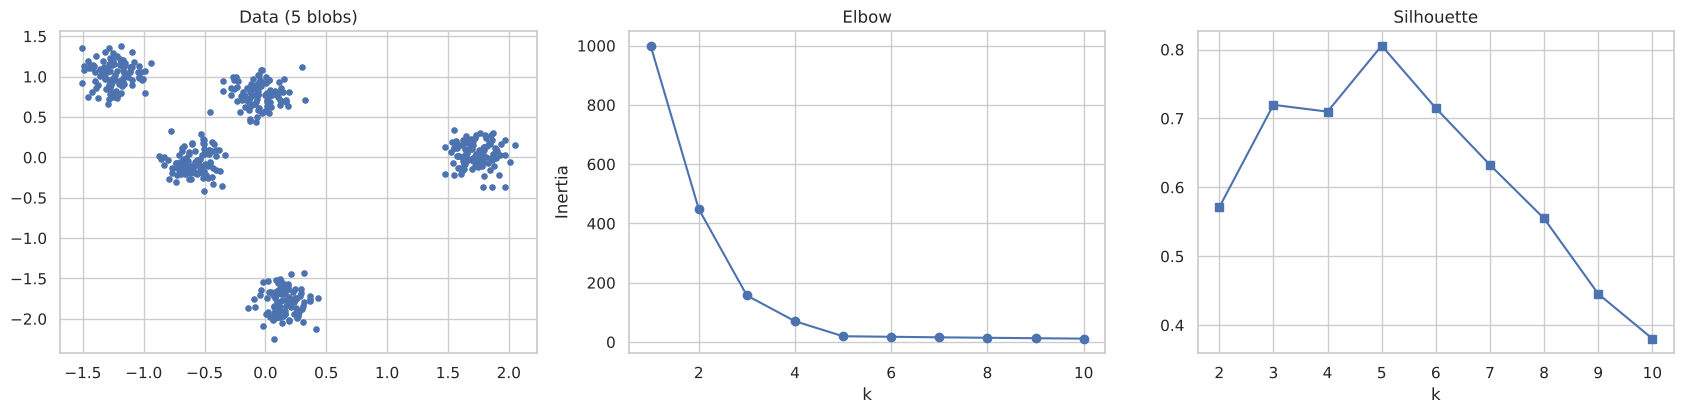

Best k by silhouette: 5


In [9]:
Xb, _ = make_blobs(n_samples=500, centers=5, cluster_std=0.8, random_state=7)
Xb = StandardScaler().fit_transform(Xb)
inert_b, sil_b = [], {}
for k in range(1, 11):
    kmb = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xb)
    inert_b.append(kmb.inertia_)
    if k > 1: sil_b[k] = silhouette_score(Xb, kmb.labels_)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].scatter(Xb[:, 0], Xb[:, 1], s=14); ax[0].set_title("Data (5 blobs)")
ax[1].plot(range(1, 11), inert_b, "o-"); ax[1].set_title("Elbow"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Inertia")
ax[2].plot(list(sil_b.keys()), list(sil_b.values()), "s-"); ax[2].set_title("Silhouette"); ax[2].set_xlabel("k")
plt.tight_layout(); plt.show()
print("Best k by silhouette:", max(sil_b, key=sil_b.get))

**How to read these:** the left plot shows 5 obvious groups. The elbow plot has a sharp bend at **k = 5** and the silhouette curve peaks at **k = 5**, so both methods agree. Compare with Iris, where overlapping classes made them disagree.

## Result / Conclusion
- The elbow method on Iris suggests k = 3; the silhouette method prefers k = 2 because two species overlap. Using both plus domain knowledge, k = 3 is chosen.
- The 3 clusters match the real species moderately well (Adjusted Rand Index 0.62): setosa is perfectly separated, and all the errors (about 17% of flowers) are between versicolor and virginica, which overlap.
- When clusters are well separated (blobs), both methods give the same, clear answer.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is clustering?**
Grouping similar data points together without using labels (unsupervised learning).

**Q2. How does the K-Means algorithm work?**
(1) Choose k. (2) Initialise k centroids. (3) Assign every point to its nearest centroid. (4) Recompute each centroid as the mean of its points. (5) Repeat steps 3 and 4 until assignments stop changing (or max iterations).

**Q3. What is inertia / WCSS?**
Within-Cluster Sum of Squares: the total of squared distances between each point and its cluster centroid. Smaller means tighter clusters.

**Q4. What is the Elbow method?**
Plot inertia for different k and choose the k at the bend of the curve, after which improvement is marginal.

**Q5. What is the silhouette score?**
A measure of how similar a point is to its own cluster compared with other clusters, from -1 to +1. The average over all points rates the clustering.

**Q6. Elbow vs silhouette?**
Elbow is visual and subjective, and only looks at compactness. Silhouette considers compactness and separation and gives a numeric score to maximise.

**Q7. Why did the elbow and silhouette methods disagree on Iris?**
Versicolor and virginica overlap, so geometrically the data looks like 2 groups (silhouette prefers k = 2) although there are 3 species (elbow suggests 3). The methods measure different things; combine them with domain knowledge.

**Q8. Why is scaling important for K-Means?**
It uses Euclidean distance, so features with larger ranges dominate.

**Q9. What is K-Means++ initialisation?**
A smarter way to choose starting centroids, spreading them far apart. It gives faster convergence and better results than random initialisation (the default in scikit-learn).

**Q10. What is `n_init`?**
The number of times K-Means is run with different starting centroids; the run with the lowest inertia is kept.

**Q11. Limitations of K-Means?**
You must choose k in advance; sensitive to initialisation and outliers; assumes spherical, similarly-sized clusters; fails on non-convex shapes (moons, rings); numeric data only.

**Q12. Does K-Means always find the global optimum?**
No. It converges to a local optimum, so we run it several times.

**Q13. Time complexity?**
$O(n\cdot k\cdot i\cdot d)$ (n points, k clusters, i iterations, d features). It scales well to large data.

**Q14. Difference between K-Means and KNN?**
K-Means is unsupervised clustering and k is the number of clusters. KNN is a supervised classifier and k is the number of neighbours.

**Q15. How do you evaluate clustering without labels?**
Silhouette score, Davies-Bouldin index (lower is better), Calinski-Harabasz index (higher is better), inertia. With labels: Adjusted Rand Index.

**Q16. K-Means vs K-Medoids?**
K-Medoids uses actual data points as centres and is more robust to outliers; K-Means uses means.

**Q17. Hard vs soft clustering?**
K-Means is hard clustering (each point belongs to exactly one cluster). Gaussian Mixture Models do soft clustering (probabilities).

**Q18. What is a centroid?**
The mean position of all points in a cluster.

**Q19. What is the objective function K-Means minimises?**
The within-cluster sum of squared distances (inertia).

**Q20. Why does inertia always decrease as k increases?**
More centroids means every point is closer to some centroid. With k = n, inertia is zero, so we cannot just pick the minimum; we look for the elbow.

**Q21. What is the Adjusted Rand Index?**
A measure of agreement between two clusterings (for example clusters vs true labels), adjusted for chance: 1 is perfect, around 0 is random.

**Q22. What if the elbow is not clear?**
Use the silhouette score, the gap statistic, other indices (Davies-Bouldin), or domain knowledge.

## B. Questions about the graphs

**G1. How do you read the Elbow curve?**
X-axis is k, Y-axis is inertia. Inertia always falls as k grows; the optimal k is at the elbow, where the drop becomes slow and the curve flattens.

**G2. How do you read the silhouette plot (score vs k)?**
Choose the k with the highest average silhouette. Values near +1 mean tight, well-separated clusters; near 0 means overlapping; negative means points are probably in the wrong cluster.

**G3. How do you read a silhouette diagram (knife plot)?**
Each knife is a cluster; each line is a sample sorted by silhouette value. The red dashed line is the average. Knives of similar width that extend past the red line are good; a thin knife or negative parts mean a poor cluster.

**G4. What do the red X marks in the scatter plot mean?**
The centroids (the mean position of each cluster). Each point belongs to its nearest centroid.

**G5. Why are the clusters plotted using PCA?**
The data has 4 features, which cannot be drawn directly; PCA projects it to 2D for visualisation.

**G6. What does the crosstab (clusters vs species) tell you?**
How well the clusters match the true labels: setosa is perfectly isolated, versicolor and virginica are partly mixed.

**G7. What does the inertia-per-iteration plot show?**
Convergence: inertia decreases at every iteration and stops changing when the algorithm has converged.

**G8. What does the blobs example show?**
When clusters are well separated, the elbow is sharp and the silhouette peak agrees with it (k = 5).

## C. Code questions

**C1. What does `km.labels_` and `km.cluster_centers_` contain?**
The cluster number of every sample, and the coordinates of the centroids.

**C2. Why `random_state=42`?**
K-Means initialisation is random; the seed makes results reproducible.

**C3. Why are cluster numbers arbitrary?**
Clusters are just labels 0..k-1 assigned by the algorithm; they have no inherent meaning or order.

**C4. Why PCA after K-Means rather than before?**
We cluster in the full 4-D space to keep all information and use PCA only to draw the result.